In [7]:
import scanpy as sc
import pandas as pd
import numpy as np

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [8]:
adata = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIII_raw.mtx').T

In [9]:
cellnames = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIII_raw_cellnames.csv")["x"]

In [10]:
genenames =  pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/you_stageIII_raw_genenames.csv")["x"]

In [11]:
adata.obs_names = cellnames
adata.var_names = genenames

In [12]:
family_info = pd.read_csv('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/you/stemdata_stageIII_metatable.csv')

In [13]:
family_info = family_info.set_index("Unnamed: 0")
family_info

,Sample,Cell.Barcode,Virus.Barcode,Cluster.Id
Unnamed: 0,,,,
AAACCCACAAATTAGG-1_1,Stage_III_Exp2,AAACCCACAAATTAGG-1_1,GTGAGAGACAGTCTGTCAGTGTGTCTGTGTGA-1-2,III-NPaHB
AAACCCACAGGTCAAG-1_1,Stage_III_Exp2,AAACCCACAGGTCAAG-1_1,GAGACTGTCTCTGACACTGTCTGTCAGTGACT-1-2,III-NPaHB
AAACCCACATTCTTCA-1_1,Stage_III_Exp2,AAACCCACATTCTTCA-1_1,NaN,NaN
AAACCCAGTTTGATCG-1_1,Stage_III_Exp2,AAACCCAGTTTGATCG-1_1,NaN,NaN
AAACCCATCGCATTGA-1_1,Stage_III_Exp2,AAACCCATCGCATTGA-1_1,NaN,NaN
...,...,...,...,...
TTTGGTTGTACAAGCG-1_8,Stage_III_Rep3_2_Exp3,TTTGGTTGTACAAGCG-1_8,NaN,NaN
TTTGGTTGTCCGGATC-1_8,Stage_III_Rep3_2_Exp3,TTTGGTTGTCCGGATC-1_8,NaN,NaN
TTTGGTTGTGGAAATT-1_8,Stage_III_Rep3_2_Exp3,TTTGGTTGTGGAAATT-1_8,NaN,NaN


In [14]:
adata.obs["barcode"] = adata.obs_names.map(family_info["Virus.Barcode"])

In [15]:
adata.obs["barcode"]

x
AAACCCACAAATTAGG-1_1    GTGAGAGACAGTCTGTCAGTGTGTCTGTGTGA-1-2
AAACCCACAGGTCAAG-1_1    GAGACTGTCTCTGACACTGTCTGTCAGTGACT-1-2
AAACCCACATTCTTCA-1_1                                     NaN
AAACCCAGTTTGATCG-1_1                                     NaN
AAACCCATCGCATTGA-1_1                                     NaN
                                        ...                 
TTTGGTTGTACAAGCG-1_8                                     NaN
TTTGGTTGTCCGGATC-1_8                                     NaN
TTTGGTTGTGGAAATT-1_8                                     NaN
TTTGTTGCATGTACGT-1_8                                     NaN
TTTGTTGGTACAGAAT-1_8                                     NaN
Name: barcode, Length: 54061, dtype: object

In [16]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [1]:
import pandas as pd

excel_path = (
    "/fast/AG_Metzger/philipp/python_files/gene_signature/"
    "mutual_information_approach/November_25_ReDo/raw_datasets/"
    "you/GSE221592_Virusbar_processed_data_combined.xlsx"
)

xls = pd.ExcelFile(excel_path)

print(xls.sheet_names)

['Clone_stage_I_Exp#1', 'Clone_stage_II_Exp#1', 'Clone_stage_II_Exp#2', 'Clone_stage_III_Exp#2', 'Clone_stage_III_Exp#3', 'Clone_stage_IV_Exp#3']


In [3]:
stage3_sheets = [
    sheet for sheet in xls.sheet_names
    if sheet.startswith("Clone_stage_III_")
]

print(stage3_sheets)

['Clone_stage_III_Exp#2', 'Clone_stage_III_Exp#3']


In [4]:
stage3_cell_types = pd.concat(
    [
        pd.read_excel(excel_path, sheet_name=sheet)
        for sheet in stage3_sheets
    ],
    ignore_index=True
)

stage3_cell_types.shape

(38128, 3)

In [5]:
stage3_cell_types["Cell.Barcode"] = (
    stage3_cell_types["Cell.Barcode"]
    .astype(str)
    .str.strip()
)

print(
    "Duplicated cell barcodes:",
    stage3_cell_types["Cell.Barcode"].duplicated().sum()
)

Duplicated cell barcodes: 0


In [17]:
cell_type_map_stage3 = (
    stage3_cell_types
    .set_index("Cell.Barcode")["Cluster.Id"]
)

adata_no_nan.obs["cell_type"] = (
    adata_no_nan.obs_names.astype(str)
    .map(cell_type_map_stage3)
)

/tmp/ipykernel_1030476/1264627625.py:6: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_no_nan.obs["cell_type"] = (


In [21]:
print(
    "Matched cell types:",
    adata_no_nan.obs["cell_type"].notna().sum(),
    "/",
    adata_no_nan.n_obs
)

adata_no_nan.obs["cell_type"].value_counts(dropna=False)

Matched cell types: 24158 / 24158


III-NPaHB     11064
III-NPvMB      6119
III-NPpHB      2309
III-Gluts      1863
III-Motors     1361
III-GABAs       835
III-Seros       607
Name: cell_type, dtype: int64

In [22]:
# check MT percentage 

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)

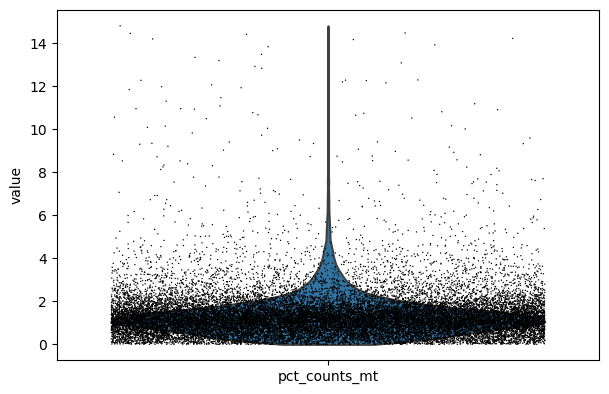

In [23]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [24]:
# Filter cells with >5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 5].copy()

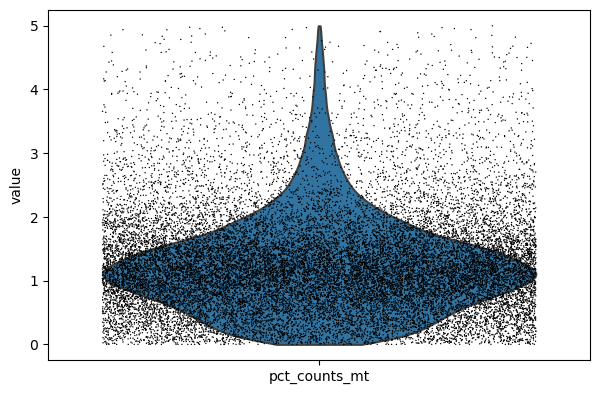

In [25]:
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [26]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

In [27]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
sc.pp.log1p(adata_no_nan)

adata_filtered = adata_no_nan

In [35]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [36]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [37]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [38]:
df["cell_type"] = adata_filtered.obs["cell_type"].to_numpy()

In [39]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [40]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [41]:
df

x,RP11-34P13.3,RP11-34P13.7,FO538757.2,AP006222.2,RP4-669L17.10,RP5-857K21.4,RP11-206L10.9,FAM87B,LINC00115,FAM41C,...,AF241725.6,AP000146.2,KRTAP19-7,DSCR8,AL773572.7,KRTAP10-2,AP001471.1,barcode,cell_type,barcode_cont
0,0.0,0.0,0.500075,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGAGAGACAGTCTGTCAGTGTGTCTGTGTGA-1-2,III-NPaHB,0
1,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.487536,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GAGACTGTCTCTGACACTGTCTGTCAGTGACT-1-2,III-NPaHB,1
2,0.0,0.0,0.327573,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTGTCTCACAGTCACTCTGTGTGTCAGTGAC-1-2;GTGTGTCTGA...,III-NPpHB,2
3,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTCTCAGACTGTGTGTGTCTGTCTCTGTCTGT-1-2,III-NPpHB,3
4,0.0,0.0,1.028643,0.541689,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTGAGTGTCTCTGTGAGTGTCTGTGTGTGT-1-2,III-NPaHB,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23878,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTGTGTGACTGAGTGACTCTGTCTGTGTGTCT-3-3;CTGTCAGTG...,III-NPvMB,15787
23879,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGAGTGTCTCAGTGTGTCTCTGTGTGTGTGT-3-3,III-NPpHB,15788
23880,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,CTGTCACTCAGTGTCTGTGTGACACTCTGTGT-3-3;CTCTCACTC...,III-NPpHB,15789
23881,0.0,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,GTGTCTCTGAGTGACTGTCTCTCTCAGTGTCT-3-3;GTGTGTGTG...,III-NPvMB,15790


In [42]:
df = df.drop("barcode", axis=1)

In [43]:
df.to_pickle('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered_with_celltype/you_stage3_barcode_all_genes.pkl')
